### Credit Stress Index Analysis V2

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
# Date range for fetching API s
start = '2007-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)

#### SJBの時系列データを取得

In [4]:
sjb = 'SJB'

response = request_api.update_stock_timeseries_data(
    code=sjb,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [5]:
sjb_df = request_api.get_stock_time_series_data(
    code=sjb,
    market=None,
    start=start,
    end=end
)
sjb_df["date"] = pd.to_datetime(sjb_df["date"])
sjb_df

取得件数: 3912


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1165760,SJB,None,2011-03-22,33.406315,33.531590,33.406315,33.531590,7700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1165761,SJB,None,2011-03-23,33.406315,33.539940,33.406315,33.539940,5900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1165762,SJB,None,2011-03-24,33.347858,33.431373,33.347858,33.431373,1700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1165763,SJB,None,2011-03-25,33.381256,33.397960,33.364553,33.397960,3600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1165764,SJB,None,2011-03-28,33.347858,33.423023,33.339505,33.423023,99800,33.464777,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3907,1169667,SJB,None,2026-10-05,15.480000,15.520000,15.480000,15.510000,128500,15.470000,...,15.075001,61.081704,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3908,1169668,SJB,None,2026-10-06,15.420000,15.450000,15.410000,15.430000,235700,15.470000,...,15.090617,65.837104,True,NaN,NaN,NaN,NaN,NaN,93.196581,False
3909,1169669,SJB,None,2026-10-07,15.450000,15.490000,15.430000,15.440000,85700,15.468000,...,15.105892,70.472979,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3910,1169670,SJB,None,2026-10-08,15.450000,15.490000,15.450000,15.450000,358900,15.456000,...,15.120783,74.494152,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### DX-Yの時系列データを取得

In [6]:
dxy = 'DX-Y'
market = 'NYB'

response = request_api.update_stock_timeseries_data(
    code=dxy,
    market=market,
    start=start,
    end=end
)
response

{'result': True}

In [7]:
dx_df = request_api.get_stock_time_series_data(
    code=dxy,
    market=market,
    start=start,
    end=end
)
dx_df["date"] = pd.to_datetime(dx_df["date"])
dx_df

取得件数: 5185


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1091754,DX-Y,NYB,2006-03-07,90.769997,90.860001,89.860001,89.910004,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1091755,DX-Y,NYB,2006-03-08,90.620003,90.800003,90.430000,90.709999,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1091756,DX-Y,NYB,2006-03-09,90.750000,90.790001,90.379997,90.599998,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1091757,DX-Y,NYB,2006-03-10,90.849998,91.160004,90.589996,90.779999,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1091758,DX-Y,NYB,2006-03-13,90.540001,90.870003,90.519997,90.830002,0,90.566000,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5180,1187717,DX-Y,NYB,2026-10-05,102.169998,102.540001,101.860001,101.919998,0,101.602000,...,99.174593,8.025271,True,NaN,NaN,NaN,NaN,NaN,NaN,False
5181,1187718,DX-Y,NYB,2026-10-06,101.830002,102.290001,101.750000,102.139999,0,101.792000,...,99.206891,16.750619,True,NaN,NaN,NaN,NaN,NaN,NaN,False
5182,1187719,DX-Y,NYB,2026-10-07,102.239998,102.500000,101.889999,101.889999,0,101.887999,...,99.275607,26.278494,True,NaN,NaN,NaN,NaN,NaN,91.82906,False
5183,1187720,DX-Y,NYB,2026-10-08,102.139999,102.470001,102.029999,102.230003,0,102.039999,...,99.330177,35.055067,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### HYGの時系列データを取得

In [8]:
hyg = 'HYG'

response = request_api.update_stock_timeseries_data(
    code=hyg,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [9]:
hyg_df = request_api.get_stock_time_series_data(
    code=hyg,
    market=None,
    start=start,
    end=end
)
hyg_df["date"] = pd.to_datetime(hyg_df["date"])
hyg_df

取得件数: 4907


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1169672,HYG,None,2007-04-11,31.084785,31.096701,31.084785,31.084785,1900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1169673,HYG,None,2007-04-12,31.105623,31.105623,31.084771,31.105623,6100,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1169674,HYG,None,2007-04-13,31.049049,31.126499,31.049049,31.096711,3400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1169675,HYG,None,2007-04-16,31.037115,31.060945,31.025199,31.060945,7600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1169676,HYG,None,2007-04-17,31.022232,31.099684,31.022232,31.025212,28100,31.074655,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4902,1174574,HYG,None,2026-10-05,76.980003,77.019997,76.809998,76.889999,39142800,77.050616,...,77.430472,-36.032613,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4903,1174575,HYG,None,2026-10-06,77.269997,77.320000,77.139999,77.150002,47352500,77.027371,...,77.356343,-44.040809,False,NaN,NaN,NaN,NaN,NaN,NaN,True
4904,1174576,HYG,None,2026-10-07,77.180000,77.209999,76.930000,77.000000,59309100,77.002000,...,77.275755,-51.707504,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4905,1174577,HYG,None,2026-10-08,77.139999,77.180000,76.980003,77.070000,44872800,77.066000,...,77.207912,-58.375309,False,NaN,NaN,NaN,NaN,NaN,NaN,True


#### TLTの時系列データを取得

In [10]:
tlt = 'TLT'

response = request_api.update_stock_timeseries_data(
    code=tlt,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [11]:
tlt_df = request_api.get_stock_time_series_data(
    code=tlt,
    market=None,
    start=start,
    end=end
)
tlt_df["date"] = pd.to_datetime(tlt_df["date"])
tlt_df

取得件数: 5182


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1175486,TLT,None,2006-03-07,45.815853,45.888240,45.660736,45.707273,1692900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1175487,TLT,None,2006-03-08,45.800343,45.955455,45.733123,45.795171,1184700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1175488,TLT,None,2006-03-09,45.815853,45.846875,45.640054,45.789999,282100,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1175489,TLT,None,2006-03-10,45.645233,45.743474,45.505631,45.665916,1086900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1175490,TLT,None,2006-03-13,45.609039,45.640061,45.505631,45.572846,1740100,45.706241,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5177,1180663,TLT,None,2026-10-05,77.110001,77.260002,76.690002,77.160004,49106700,77.618303,...,78.701412,-72.457953,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5178,1180664,TLT,None,2026-10-06,77.279999,77.580002,77.070000,77.169998,31085900,77.411296,...,78.433292,-74.293520,False,NaN,NaN,NaN,NaN,-85.0,NaN,False
5179,1180665,TLT,None,2026-10-07,77.150002,77.320000,76.430000,76.459999,40200000,77.134001,...,78.110772,-75.147272,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5180,1180666,TLT,None,2026-10-08,77.870003,77.910004,77.070000,77.190002,49484200,77.184001,...,77.891491,-75.078972,False,NaN,NaN,NaN,NaN,NaN,NaN,True


#### FREDの月次データを取得

In [12]:
fred_url = "https://api.stlouisfed.org/fred/series/observations"
series_mapping = {
    "DFF": "effective_federal_funds_rate",  # 実効FF金利
    "DFII10": "real_10y",                   # 10年TIPS実質金利
    "FEDFUNDS": "ff_rate",                  # FF金利
    "DFEDTARU": "maximum_interest_rate",    # 上限金利
    "DFEDTARL": "minimum_interest_rate",    # 下限金利
    "DGS2": "us_treasury_2y",               # 2年米国債
    "DGS5": "us_treasury_5y",               # 5年米国債
    "DGS10": "us_treasury_10y",             # 10年米国債
    "DGS30": "us_treasury_30y",             # 30年米国債
    "M1SL": "m1_money_stock",               # M1マネーストック
    "M2SL": "m2_money_stock",               # M2マネーストック
}
observation_start = "2007-01-01"
observation_end = end
base_fred_params = {
    "api_key": FRED_API_KEY,
    "file_type": "json",
    "observation_start": observation_start,
    "observation_end": observation_end,
    "frequency": "m",
    "aggregation_method": "avg",
}
fred_dfs = []
for series_id, series_name in series_mapping.items():
    fred_params = base_fred_params.copy()
    fred_params["series_id"] = series_id
    fred_res = requests.get(fred_url, params=fred_params)
    fred_df = pd.DataFrame(fred_res.json()["observations"]).assign(**{
        "date": lambda df: pd.to_datetime(df["date"]),
        "value": lambda df: pd.to_numeric(df["value"], errors="coerce"),
        "interest_rate_type": series_name,
    })
    fred_dfs.append(fred_df)
    time.sleep(5)
    
us_treasury_df = pd.concat(fred_dfs)
us_treasury_df

,realtime_start,realtime_end,date,value,interest_rate_type
0,2026-10-10,2026-10-10,2007-01-01,5.25,effective_federal_funds_rate
1,2026-10-10,2026-10-10,2007-02-01,5.26,effective_federal_funds_rate
2,2026-10-10,2026-10-10,2007-03-01,5.26,effective_federal_funds_rate
3,2026-10-10,2026-10-10,2007-04-01,5.25,effective_federal_funds_rate
4,2026-10-10,2026-10-10,2007-05-01,5.25,effective_federal_funds_rate
...,...,...,...,...,...
231,2026-10-10,2026-10-10,2026-04-01,22756.60,m2_money_stock
232,2026-10-10,2026-10-10,2026-05-01,23013.70,m2_money_stock
233,2026-10-10,2026-10-10,2026-06-01,23114.90,m2_money_stock
234,2026-10-10,2026-10-10,2026-07-01,23217.90,m2_money_stock


#### CSI v2 (Credit Stress Index v2)

##### 指数構成
###### ストレス要因
1. DXY Z
2. FF Z
3. REAL10Y Z
4. 10Y-2Y Z
###### 緩和要因
1. M2 YoY Z

#### 0. ETF月次データ準備

In [13]:
etf_monthly = (
    hyg_df[
        ["date","close"]
    ]
    .rename(columns={"close":"hyg"})
)

dxy_monthly = (
    dx_df[
        ["date","close"]
    ]
    .rename(columns={"close":"dxy"})
)

tlt_monthly = (
    tlt_df[
        ["date","close"]
    ]
    .rename(columns={"close":"tlt"})
)

sjb_monthly = (
    sjb_df[
        ["date","close"]
    ]
    .rename(columns={"close":"sjb"})
)

for df in [
    etf_monthly,
    dxy_monthly,
    tlt_monthly,
    sjb_monthly
]:
    df["date"] = pd.to_datetime(df["date"])

#### 1. ETFデータを月次化

In [14]:
def resample_monthly(df, col):

    return (
        df.set_index("date")
        [[col]]
        .resample("ME")
        .last()
        .reset_index()
    )

hyg_m = resample_monthly(etf_monthly, "hyg")
dxy_m = resample_monthly(dxy_monthly, "dxy")
tlt_m = resample_monthly(tlt_monthly, "tlt")
sjb_m = resample_monthly(sjb_monthly, "sjb")

#### 2. FREDと結合

In [15]:
#
# ETF : 月末
# FRED : 月初
#
# → FREDを月末へ寄せる
#

fred_pivot = (
    us_treasury_df
    .pivot(
        index="date",
        columns="interest_rate_type",
        values="value"
    )
    .reset_index()
)

fred_pivot["date"] = (
    pd.to_datetime(fred_pivot["date"])
    + pd.offsets.MonthEnd(0)
)

model_df = (
    hyg_m
    .merge(dxy_m, on="date", how="inner")
    .merge(tlt_m, on="date", how="inner")
    .merge(sjb_m, on="date", how="inner")
    .merge(
        fred_pivot,
        on="date",
        how="left"
    )
)

model_df = (
    model_df
    .sort_values("date")
    .reset_index(drop=True)
)

print("model_df shape =", model_df.shape)

display(model_df.head())
display(model_df.tail())

model_df shape = (188, 16)


,date,hyg,dxy,tlt,sjb,effective_federal_funds_rate,ff_rate,m1_money_stock,m2_money_stock,maximum_interest_rate,minimum_interest_rate,real_10y,us_treasury_10y,us_treasury_2y,us_treasury_30y,us_treasury_5y
0,2011-03-31,38.673623,76.139999,59.322786,33.322808,0.14,0.14,1901.2,8967.7,0.25,0.0,0.96,3.41,0.70,4.51,2.11
1,2011-04-30,39.223561,73.059998,60.086646,32.713123,0.10,0.10,1901.9,9033.6,0.25,0.0,0.86,3.46,0.73,4.50,2.17
2,2011-05-31,39.313942,74.730003,62.093303,32.495994,0.09,0.09,1947.0,9109.4,0.25,0.0,0.78,3.17,0.56,4.29,1.84
3,2011-06-30,38.828467,74.470001,61.056642,32.830053,0.09,0.09,1969.0,9184.2,0.25,0.0,0.76,3.00,0.41,4.23,1.58
4,2011-07-31,38.982782,74.150002,62.994425,32.537760,0.07,0.07,2001.8,9346.9,0.25,0.0,0.62,3.00,0.41,4.27,1.54


,date,hyg,dxy,tlt,sjb,effective_federal_funds_rate,ff_rate,m1_money_stock,m2_money_stock,maximum_interest_rate,minimum_interest_rate,real_10y,us_treasury_10y,us_treasury_2y,us_treasury_30y,us_treasury_5y
183,2026-06-30,78.465107,101.120003,85.805249,15.009434,3.63,3.63,19793.0,23114.9,3.75,3.50,2.18,4.47,4.11,4.95,4.21
184,2026-07-31,78.296741,100.019997,81.477568,15.108637,3.63,3.63,19886.5,23217.9,3.75,3.50,2.35,4.60,4.22,5.10,4.33
185,2026-08-31,78.924394,99.699997,81.825639,15.039195,3.63,3.63,19991.1,23342.8,3.75,3.50,2.40,4.68,4.22,5.22,4.38
186,2026-09-30,77.126854,101.410004,77.846475,15.450000,3.75,3.75,NaN,NaN,3.87,3.62,2.64,4.99,4.65,5.37,4.80
187,2026-10-31,77.209999,102.129997,77.709999,15.470000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
display(hyg_m.head())
display(fred_pivot.head())

,date,hyg
0,2007-04-30,31.445211
1,2007-05-31,31.631284
2,2007-06-30,30.669168
3,2007-07-31,29.310791
4,2007-08-31,30.864440


interest_rate_type,date,effective_federal_funds_rate,ff_rate,m1_money_stock,m2_money_stock,maximum_interest_rate,minimum_interest_rate,real_10y,us_treasury_10y,us_treasury_2y,us_treasury_30y,us_treasury_5y
0,2007-01-31,5.25,5.25,1371.7,7115.6,NaN,NaN,2.44,4.76,4.88,4.85,4.75
1,2007-02-28,5.26,5.26,1363.0,7131.9,NaN,NaN,2.36,4.72,4.85,4.82,4.71
2,2007-03-31,5.26,5.26,1366.5,7164.7,NaN,NaN,2.18,4.56,4.57,4.72,4.48
3,2007-04-30,5.25,5.25,1378.0,7239.9,NaN,NaN,2.26,4.69,4.67,4.87,4.59
4,2007-05-31,5.25,5.25,1380.9,7257.1,NaN,NaN,2.37,4.75,4.77,4.90,4.67


#### 3. 派生指標作成
- M2 YoY
- Yield Curve
- Real Yield

In [17]:
#
# マクロ派生指標
#

model_df["m2_yoy"] = (
    model_df["m2_money_stock"]
    .pct_change(12)
)

#
# イールドカーブ
#

model_df["term_spread"] = (
    model_df["us_treasury_10y"]
    - model_df["us_treasury_2y"]
)

#
# CSI用
#
# 逆イールドになるほど上昇
#

model_df["term_spread_inv"] = (
    -1.0 * model_df["term_spread"]
)

#
# 実質金利
#

model_df["real_10y"] = (
    model_df["real_10y"]
)

#
# クレジット確認用
#

model_df["hyg_tlt_ratio"] = (
    model_df["hyg"]
    / model_df["tlt"]
)

model_df["hyg_sjb_ratio"] = (
    model_df["hyg"]
    / model_df["sjb"]
)

display(
    model_df[
        [
            "date",
            "m2_yoy",
            "term_spread",
            "term_spread_inv",
            "real_10y"
        ]
    ].tail()
)

,date,m2_yoy,term_spread,term_spread_inv,real_10y
183,2026-06-30,0.053426,0.36,-0.36,2.18
184,2026-07-31,0.054132,0.38,-0.38,2.35
185,2026-08-31,0.056589,0.46,-0.46,2.40
186,2026-09-30,NaN,0.34,-0.34,2.64
187,2026-10-31,NaN,NaN,NaN,NaN


#### 4. 欠損確認

In [18]:
na_before = (
    model_df
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("===== BEFORE FILL =====")
display(na_before)

#
# 前方補完
#

model_df = model_df.ffill()

na_after = (
    model_df
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("===== AFTER FILL =====")
display(na_after.head(20))

print("rows =", len(model_df))

===== BEFORE FILL =====


m2_yoy                          14
m1_money_stock                   2
m2_money_stock                   2
minimum_interest_rate            1
us_treasury_5y                   1
term_spread_inv                  1
term_spread                      1
effective_federal_funds_rate     1
ff_rate                          1
maximum_interest_rate            1
real_10y                         1
us_treasury_10y                  1
us_treasury_2y                   1
us_treasury_30y                  1
hyg_tlt_ratio                    0
date                             0
hyg                              0
sjb                              0
tlt                              0
dxy                              0
hyg_sjb_ratio                    0
dtype: int64

===== AFTER FILL =====


m2_yoy                          12
date                             0
real_10y                         0
hyg_tlt_ratio                    0
term_spread_inv                  0
term_spread                      0
us_treasury_5y                   0
us_treasury_30y                  0
us_treasury_2y                   0
us_treasury_10y                  0
minimum_interest_rate            0
hyg                              0
maximum_interest_rate            0
m2_money_stock                   0
m1_money_stock                   0
ff_rate                          0
effective_federal_funds_rate     0
sjb                              0
tlt                              0
dxy                              0
dtype: int64

rows = 188


#### 5. rolling z-score関数

In [19]:
def rolling_zscore(series, window=24):

    mean = (
        series
        .rolling(window)
        .mean()
    )

    std = (
        series
        .rolling(window)
        .std()
    )

    return (
        (series - mean)
        / std
    )

#### 6. 各因子z-score

In [20]:
factors = [
    "dxy",
    "ff_rate",
    "real_10y",
    "term_spread_inv",
    "m2_yoy"
]

for col in factors:

    model_df[f"{col}_z"] = (
        rolling_zscore(
            model_df[col]
        )
    )

display(
    model_df[
        [
            "date",
            "dxy_z",
            "ff_rate_z",
            "real_10y_z",
            "term_spread_inv_z",
            "m2_yoy_z"
        ]
    ].tail(10)
)

,date,dxy_z,ff_rate_z,real_10y_z,term_spread_inv_z,m2_yoy_z
178,2026-01-31,-1.591643,-1.719586,-0.306367,-1.261909,0.769193
179,2026-02-28,-1.109705,-1.563075,-0.858079,-1.143600,1.140220
180,2026-03-31,-0.321981,-1.434989,-0.274497,-0.755457,0.971138
181,2026-04-30,-0.717191,-1.328599,-0.022614,-0.636425,1.021803
182,2026-05-31,-0.617805,-1.256357,0.711427,-0.451599,1.773867
183,2026-06-30,0.011370,-1.183961,1.582216,0.080068,1.671786
184,2026-07-31,-0.251129,-1.130956,2.286733,0.126251,1.725404
185,2026-08-31,-0.322191,-1.105827,2.208628,-0.177122,1.930710
186,2026-09-30,0.155335,-0.793870,2.852635,0.616978,1.801345
187,2026-10-31,0.390977,-0.739936,2.377679,0.727146,1.662510


#### 7. 因子可視化

In [21]:
factor_cols = [
    c
    for c in model_df.columns
    if c.endswith("_z")
]

print("factor columns")
print(factor_cols)

summary = (
    model_df[factor_cols]
    .describe()
)

display(summary)

print("NaN count")

display(
    model_df[factor_cols]
    .isna()
    .sum()
)

display(
    model_df[
        ["date"] + factor_cols
    ].tail(20)
)

factor columns
['dxy_z', 'ff_rate_z', 'real_10y_z', 'term_spread_inv_z', 'm2_yoy_z']


,dxy_z,ff_rate_z,real_10y_z,term_spread_inv_z,m2_yoy_z
count,165.000000,165.000000,165.000000,165.000000,153.000000
mean,0.261937,0.457490,0.330551,0.104997,0.072035
std,1.315629,1.665107,1.314996,1.412766,1.449423
min,-2.736095,-3.215006,-2.491309,-2.844880,-2.063765
25%,-0.667487,-1.105827,-0.754968,-1.232261,-1.281794
50%,0.363727,0.745731,0.502725,0.273068,-0.378388
75%,1.201692,1.750856,1.306629,1.326667,1.420776
max,3.211295,4.352230,3.310111,2.222646,3.899611


NaN count


dxy_z                23
ff_rate_z            23
real_10y_z           23
term_spread_inv_z    23
m2_yoy_z             35
dtype: int64

,date,dxy_z,ff_rate_z,real_10y_z,term_spread_inv_z,m2_yoy_z
168,2025-03-31,-0.110332,-1.966248,0.194528,-1.583658,1.237597
169,2025-04-30,-2.148025,-1.782725,0.455277,-1.848933,1.286221
170,2025-05-31,-1.861237,-1.603761,0.705781,-1.652747,1.184240
171,2025-06-30,-2.260106,-1.455510,0.550271,-1.514773,1.180113
172,2025-07-31,-1.288843,-1.328198,0.050269,-1.483627,1.181914
173,2025-08-31,-1.736084,-1.215223,-0.716159,-1.501552,1.063243
174,2025-09-30,-1.551451,-1.320559,-1.343652,-1.374564,0.996651
175,2025-10-31,-0.988731,-1.442955,-1.261992,-1.232261,0.964448
176,2025-11-30,-0.906410,-1.673148,-0.761944,-1.135052,0.730838
177,2025-12-31,-1.221478,-1.768523,-0.331701,-1.295832,0.783723


#### 8. 因子間相関

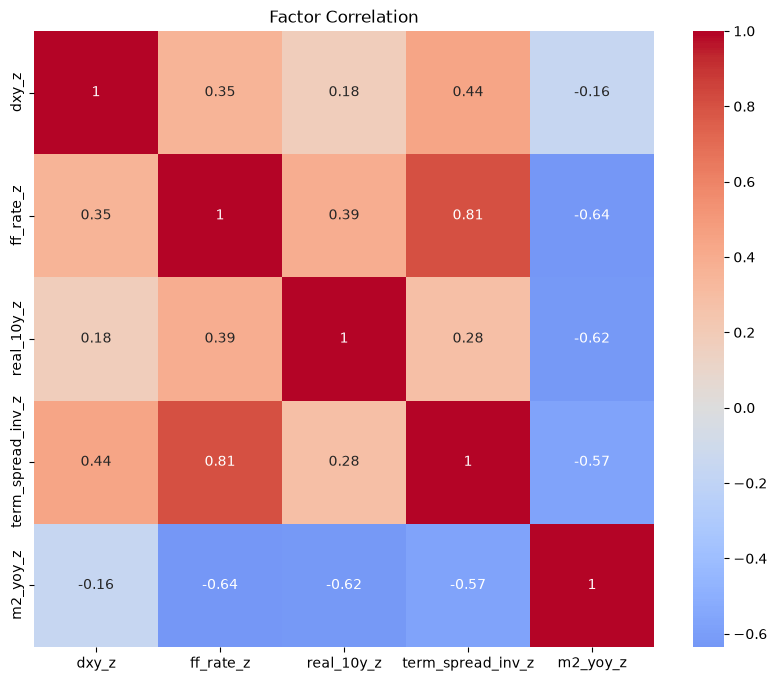

In [22]:
corr = (
    model_df[
        factor_cols
    ]
    .corr()
)

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Factor Correlation")
plt.savefig(f"{output_dir}/factor_correlation.png")

plt.show()

#### 9. CSI作成

In [23]:
model_df["CSI"] = (
      model_df["dxy_z"]
    + model_df["ff_rate_z"]
    + model_df["real_10y_z"]
    + model_df["term_spread_inv_z"]
    - model_df["m2_yoy_z"]
)

#### 10. CSI確認

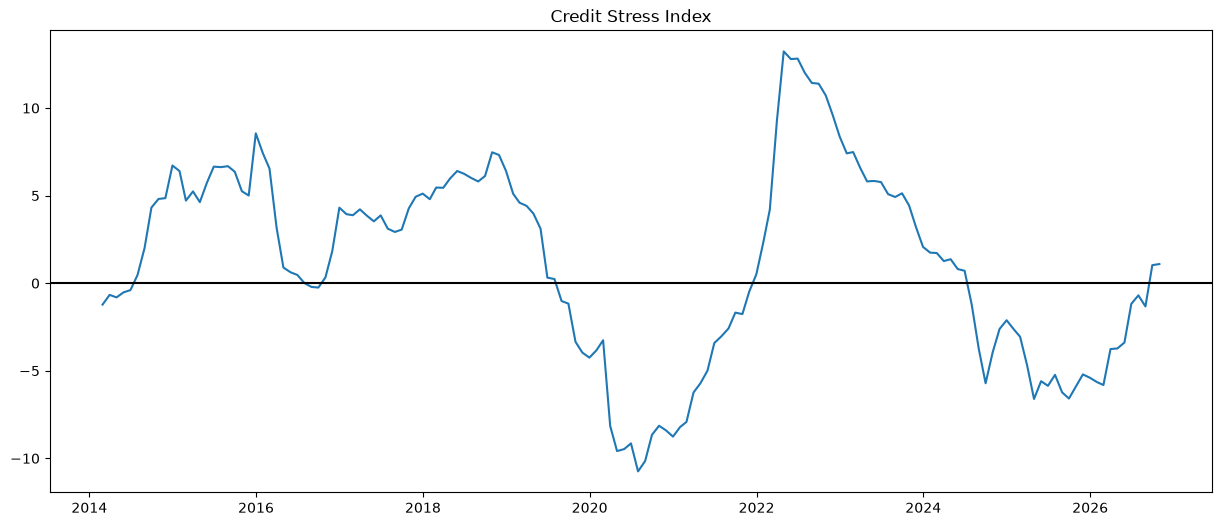

In [24]:
plt.figure(figsize=(15,6))

plt.plot(
    model_df["date"],
    model_df["CSI"]
)

plt.axhline(
    0,
    color="black"
)

plt.title("Credit Stress Index")
plt.savefig(f"{output_dir}/credit_stress_index.png")

plt.show()

#### 10.5 レジーム判定

In [25]:
#### Display the first few rows of the datasets

#### 11. 将来リターン作成
- ret_1m
- ret_3m
- ret_6m

In [26]:
horizon = 3

model_df["future_return"] = (
    model_df["hyg"]
    .shift(-horizon)
    /
    model_df["hyg"]
    -
    1
)

#### 12. Lead/Lag検証

In [27]:
lags = range(-12,13)

leadlag = []

for lag in lags:

    corr = (
        model_df["CSI"]
        .shift(lag)
        .corr(
            model_df["future_return"]
        )
    )

    leadlag.append(corr)

leadlag_df = pd.DataFrame({
    "lag":lags,
    "corr":leadlag
})

display(
    leadlag_df.sort_values(
        "corr",
        ascending=False
    ).head()
)

,lag,corr
24,12,0.294181
23,11,0.249479
22,10,0.194261
21,9,0.155275
20,8,0.134625


In [28]:
# CSI vs HYG
model_df["CSI"].corr(
    model_df["future_return"]
)


np.float64(-0.1578917081569964)

In [29]:
# DXY単独
model_df["dxy_z"].corr(
    model_df["future_return"]
)

np.float64(-0.10425110234414656)

In [30]:
# FF単独
model_df["ff_rate_z"].corr(
    model_df["future_return"]
)

np.float64(-0.07156054131924694)

In [31]:
# Real10Y単独
model_df["real_10y_z"].corr(
    model_df["future_return"]
)

np.float64(-0.0040386615725936355)

In [32]:
# YieldCurve単独
model_df["term_spread_inv_z"].corr(
    model_df["future_return"]
)

np.float64(-0.19811112544232606)

In [33]:
# M2単独
model_df["m2_yoy_z"].corr(
    model_df["future_return"]
)

np.float64(0.2587750752166371)

#### 13. 回帰分析

In [34]:
from sklearn.linear_model import LinearRegression

feature_cols = [
    "dxy_z",
    "ff_rate_z",
    "real_10y_z",
    "term_spread_inv_z",
    "m2_yoy_z"
]

reg_df = (
    model_df[
        feature_cols +
        ["future_return"]
    ]
    .dropna()
)

X = reg_df[feature_cols]

y = reg_df["future_return"]

model = LinearRegression()

model.fit(X,y)

coef_df = pd.DataFrame({

    "factor":feature_cols,

    "coef":model.coef_

})

display(
    coef_df.sort_values(
        "coef",
        ascending=False
    )
)

,factor,coef
4,m2_yoy_z,0.010441
1,ff_rate_z,0.006512
2,real_10y_z,0.005052
0,dxy_z,-0.002116
3,term_spread_inv_z,-0.004761


#### 14. Walk Forward検証（推奨）

In [35]:
from sklearn.metrics import r2_score

preds = []
acts = []

window = 60

for i in range(
    window,
    len(reg_df)-1
):

    train = reg_df.iloc[
        i-window:i
    ]

    test = reg_df.iloc[
        i:i+1
    ]

    X_train = train[feature_cols]
    y_train = train["future_return"]

    X_test = test[feature_cols]

    model = LinearRegression()

    model.fit(
        X_train,
        y_train
    )

    pred = model.predict(X_test)[0]

    preds.append(pred)

    acts.append(
        test["future_return"].iloc[0]
    )

walk_df = pd.DataFrame({

    "actual":acts,
    "pred":preds
})

print(
    "WalkForward R2:",
    r2_score(
        walk_df["actual"],
        walk_df["pred"]
    )
)

WalkForward R2: -0.43207330840468683


#### 15. Walk Forward検証結果を可視化

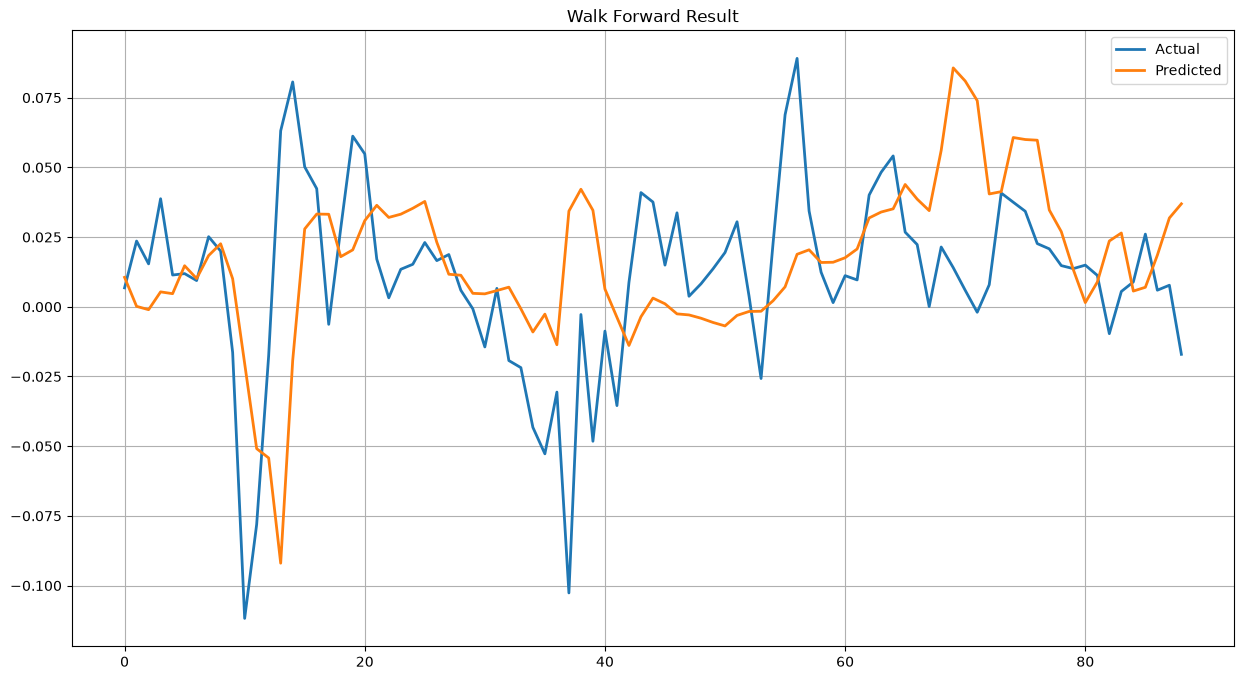

In [36]:
plt.figure(
    figsize=(15,8)
)

plt.plot(
    walk_df.index,
    walk_df["actual"],
    label="Actual",
    linewidth=2
)

plt.plot(
    walk_df.index,
    walk_df["pred"],
    label="Predicted",
    linewidth=2
)

plt.legend()

plt.grid()

plt.title(
    "Walk Forward Result"
)

plt.savefig(f"{output_dir}/walk_forward_result.png")
plt.show()

walk_df.to_csv(
    output_dir /
    "walk_forward_result.csv"
)

In [37]:
from sklearn.metrics import (
    r2_score,
    mean_squared_error
)

print(
    "R2      =",
    r2_score(
        walk_df["actual"],
        walk_df["pred"]
    )
)

corr = walk_df["actual"].corr(
    walk_df["pred"]
)

print("Corr =", corr)

hit_rate = (
    np.sign(walk_df["actual"])
    ==
    np.sign(walk_df["pred"])
).mean()

print(
    "DirectionHitRate =",
    hit_rate
)

R2      = -0.43207330840468683
Corr = 0.15481522558153726
DirectionHitRate = 0.7303370786516854


In [38]:
signal_df = walk_df.copy()

signal_df["actual_sign"] = (
    signal_df["actual"] > 0
)

signal_df["pred_sign"] = (
    signal_df["pred"] > 0
)

pd.crosstab(
    signal_df["actual_sign"],
    signal_df["pred_sign"]
)

pred_sign,False,True
actual_sign,,
False,9,12
True,12,56


In [39]:
print(model_df.columns.tolist())

['date', 'hyg', 'dxy', 'tlt', 'sjb', 'effective_federal_funds_rate', 'ff_rate', 'm1_money_stock', 'm2_money_stock', 'maximum_interest_rate', 'minimum_interest_rate', 'real_10y', 'us_treasury_10y', 'us_treasury_2y', 'us_treasury_30y', 'us_treasury_5y', 'm2_yoy', 'term_spread', 'term_spread_inv', 'hyg_tlt_ratio', 'hyg_sjb_ratio', 'dxy_z', 'ff_rate_z', 'real_10y_z', 'term_spread_inv_z', 'm2_yoy_z', 'CSI', 'future_return']


In [40]:
regime_stats = (
    model_df
    .groupby("regime")["future_return"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
)

display(regime_stats)

KeyError: 'regime'